# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

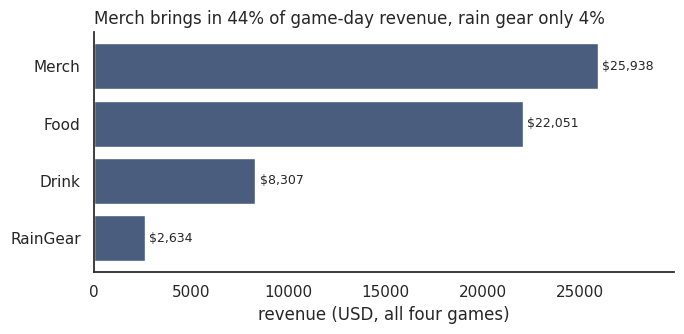

In [2]:
by_cat = df.groupby('category')['revenue'].sum().sort_values()   # smallest first, biggest ends up on top
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(by_cat.index, by_cat.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in by_cat.values], padding=3, fontsize=9)
ax.set_xlim(0, by_cat.max() * 1.15)
finish(ax, f'{by_cat.idxmax()} brings in {by_cat.max()/by_cat.sum():.0%} of game-day revenue, rain gear only {by_cat["RainGear"]/by_cat.sum():.0%}',
       xlabel='revenue (USD, all four games)', ylabel='')
plt.show()

**Caption:** Supports deciding where to put stock and stand space: merch and food are about 80% of revenue, so protect those lines first

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

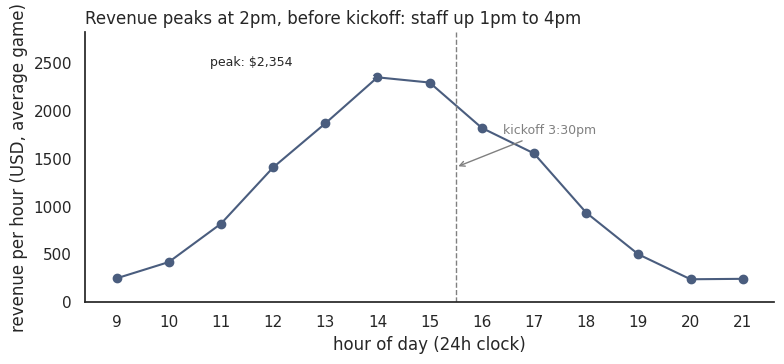

In [3]:
rev_hour = df.groupby('hour')['revenue'].sum() / df['game'].nunique()   # revenue per hour, average game
peak_hour = rev_hour.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(rev_hour.index, rev_hour.values, marker='o', color=BLUE)
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, rev_hour.max() * 0.6), xytext=(16.4, rev_hour.max() * 0.75),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')
ax.annotate(f'peak: ${rev_hour.max():,.0f}', xy=(peak_hour, rev_hour.max()),
            xytext=(peak_hour - 3.2, rev_hour.max() * 1.05), arrowprops=dict(arrowstyle='->'), fontsize=9)
ax.set_ylim(0, rev_hour.max() * 1.2)
ax.set_xticks(hours)
finish(ax, f'Revenue peaks at {peak_hour - 12}pm, before kickoff: staff up 1pm to 4pm',
       xlabel='hour of day (24h clock)', ylabel='revenue per hour (USD, average game)')
plt.show()

**Caption:** Supports the shift schedule: bring the full crew in by 1pm, because revenue is already near its peak two hours before kickoff

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

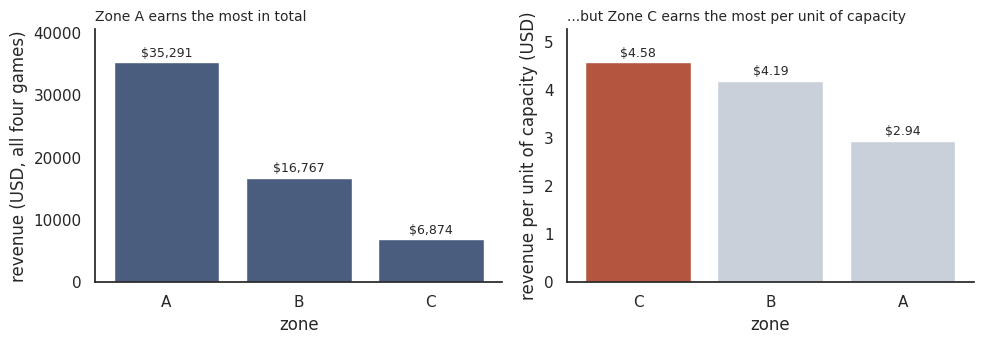

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

z = df.groupby('zone')['revenue'].sum().to_frame('revenue')
z['capacity'] = pd.Series(zone_capacity)
z['rev_per_cap'] = z['revenue'] / z['capacity']
zr = z['revenue'].sort_values(ascending=False)
zp = z['rev_per_cap'].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

b0 = axes[0].bar(zr.index, zr.values, color=BLUE)
axes[0].bar_label(b0, labels=[f'${v:,.0f}' for v in zr.values], padding=2, fontsize=9)
axes[0].set_ylim(0, zr.max() * 1.15)
finish(axes[0], f'Zone {zr.idxmax()} earns the most in total', xlabel='zone',
       ylabel='revenue (USD, all four games)', fontsize=10)

b1 = axes[1].bar(zp.index, zp.values, color=[RUST if i == zp.idxmax() else GRAY for i in zp.index])
axes[1].bar_label(b1, labels=[f'${v:.2f}' for v in zp.values], padding=2, fontsize=9)
axes[1].set_ylim(0, zp.max() * 1.15)
finish(axes[1], f'...but Zone {zp.idxmax()} earns the most per unit of capacity', xlabel='zone',
       ylabel='revenue per unit of capacity (USD)', fontsize=10)
plt.show()

**Caption, and which panel I would present:** Supports deciding where to add stands or staff. I would show the per-capacity panel to a manager asking: which zone is underperforming? The raw panel is for: where does our money come from?

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

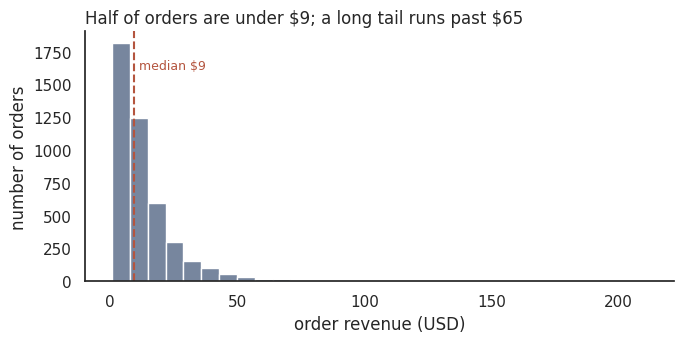

In [5]:
median, p99 = df['revenue'].median(), df['revenue'].quantile(0.99)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x='revenue', bins=30, color=BLUE, ax=ax)
ax.axvline(median, color=RUST, ls='--')
ax.text(median + 2, ax.get_ylim()[1] * 0.85, f'median ${median:.0f}', color=RUST, fontsize=9)
finish(ax, f'Half of orders are under ${median:.0f}; a long tail runs past ${p99:.0f}',
       xlabel='order revenue (USD)', ylabel='number of orders')
plt.show()

**Caption:** Supports planning around volume rather than ticket size: most orders are small, so speed of service matters more than a few big orders. The mean sits above the median because of the tail, which a category total would hide

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

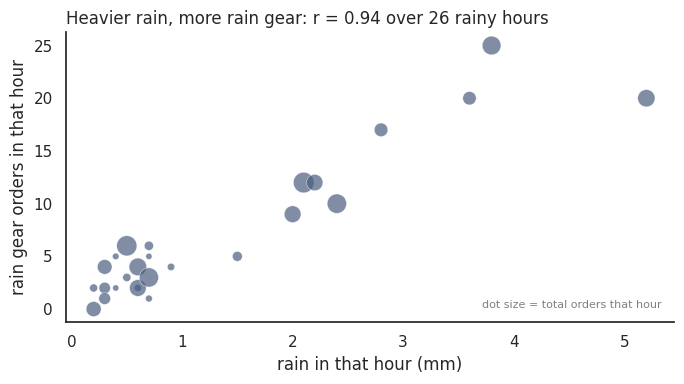

In [6]:
hr = (df[df['weather'] == 'rain'].groupby(['game', 'hour'])
        .agg(rain_mm=('rain_mm', 'first'),
             raingear=('category', lambda s: (s == 'RainGear').sum()),
             total=('category', 'size'))
        .reset_index())
r = hr['rain_mm'].corr(hr['raingear'])

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=hr, x='rain_mm', y='raingear', size='total', sizes=(20, 220),
                color=BLUE, alpha=0.7, legend=False, ax=ax)
ax.text(0.98, 0.05, 'dot size = total orders that hour', transform=ax.transAxes,
        ha='right', fontsize=8, color='gray')
finish(ax, f'Heavier rain, more rain gear: r = {r:.2f} over {len(hr)} rainy hours',
       xlabel='rain in that hour (mm)', ylabel='rain gear orders in that hour')
plt.show()

**Caption:** Supports stocking rain gear from the forecast: orders climb steadily with rainfall, so order extra when heavy rain is predicted. This rests on 26 game-hours from two games, so treat it as a rule of thumb

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data?


**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.



a. Chart 1 changed my mind. Monday's example title said food drives revenue, but by total revenue merch is first (44%) and food second (37%). Food has the most orders, but merch orders are worth about \\$23 each against about \\$10 for food, so order counts and revenue tell different stories.

b. The raw-revenue panel is right when the question is "where does our money come from?", for example when allocating inventory or reporting totals, because it counts every dollar. The per-capacity panel is right when the question is "which zone is working hardest or underperforming for its size?", for example when deciding where to add stands. Zone A leads on total revenue only because it is the biggest zone. Per unit of capacity it earns the least (\$2.94, against $4.58 in Zone C).